In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Arial"

from statannotations.Annotator import Annotator
from itertools import combinations

from additives_microbiota.group_statistics import (
    test_quartile_differences,
    test_group_differences,
)
from additives_microbiota.constants import ADDITIVE_VARS, MIXTURES
from additives_microbiota.plotting import process_string, process_string_pretty_vars

## Load Metadata

In [2]:
meta = pd.read_csv("../../data/metadata_files/meta_zscores.csv", index_col=0)

bmi_order = ["Underweight", "Normal", "Overweight", "Obese"]
meta["bmi_cat"] = pd.Categorical(meta["bmi_cat"], categories=bmi_order, ordered=True)

meta["HEI_Quartile"] = meta["HEI_Quartile"].astype("category")
meta["HEI_Quartile"] = meta["HEI_Quartile"].cat.set_categories(
    ["Q1", "Q2", "Q3", "Q4"], ordered=True
)

meta["age_group_2"] = meta["age_group_2"].astype("category")
meta["age_group_2"] = meta["age_group_2"].cat.set_categories(
    ["<35", "35-50", ">50"], ordered=True
)

## Merging with average additive consumption
# meta = meta.merge(k_across_days_avg.reset_index(), on="subject_key")
# meta = meta.merge(food_category_consumption_by_user, on="subject_key")

## Analysis

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:5.749e-03 U_stat=3.380e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:2.499e-03 U_stat=3.461e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:4.403e-01 U_stat=3.110e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:2.189e-08 U_stat=3.804e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.908e-04 U_stat=3.586e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:6.882e-10 U_stat=3.907e+04
daily_HEI_Quartile -> total_additive_intake_log	Significant differences exist. Kruskal-Wallis statistic: 50.265 p-value: 0.000


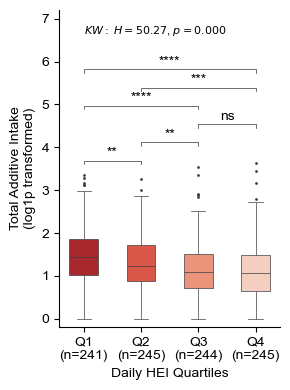

In [3]:
fig, ax = plt.subplots(figsize=(3, 4))
test_group_differences(
    meta,
    "daily_HEI_Quartile",
    "total_additive_intake",
    palette="Reds_r",
    showfliers=True,
    ax=ax,
    xlabel="Daily HEI Quartiles",
    ylabel=process_string("total_additive_intake", newLineSep=3),
    log_transform=True,
)
sns.despine()
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/group_comparison_total_additives_vs_daily_HEI_Quartile.png",
    dpi=300,
    bbox_inches="tight",
)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

german vs. latin: Mann-Whitney-Wilcoxon test two-sided, P_val:4.461e-03 U_stat=1.221e+05
language -> total_additive_intake_log	Significant differences exist. Mann-Whitney U statistic: 98426.000 p-value: 0.004


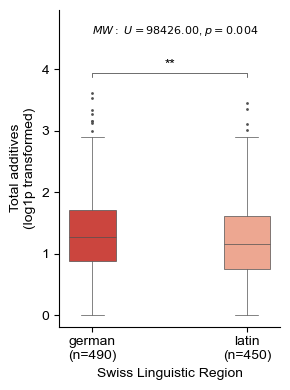

In [4]:
fig, ax = plt.subplots(figsize=(3, 4))
test_group_differences(
    meta[meta["language"].notna()],
    "language",
    "total_additive_intake",
    palette="Reds_r",
    showfliers=True,
    ax=ax,
    xlabel="Swiss Linguistic Region",
    # ylabel=process_string("total_additive_intake", newLineSep=3),
    log_transform=True,
    box_width=0.3,
)
sns.despine()
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/group_comparison_total_additives_vs_language.png",
    dpi=300,
    bbox_inches="tight",
)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

18-34 vs. 35-49: Mann-Whitney-Wilcoxon test two-sided, P_val:2.663e-01 U_stat=7.800e+04
35-49 vs. 50-64: Mann-Whitney-Wilcoxon test two-sided, P_val:1.428e-02 U_stat=3.649e+04
50-64 vs. 65+: Mann-Whitney-Wilcoxon test two-sided, P_val:1.027e-01 U_stat=2.390e+03
18-34 vs. 50-64: Mann-Whitney-Wilcoxon test two-sided, P_val:8.905e-04 U_stat=4.332e+04
35-49 vs. 65+: Mann-Whitney-Wilcoxon test two-sided, P_val:8.933e-03 U_stat=5.290e+03
18-34 vs. 65+: Mann-Whitney-Wilcoxon test two-sided, P_val:3.969e-03 U_stat=6.198e+03
age_group -> total_additive_intake_log	Significant differences exist. Kruskal-Wallis statistic: 17.967 p-value: 0.000


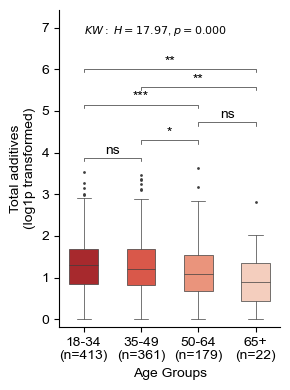

In [5]:
fig, ax = plt.subplots(figsize=(3, 4))
test_group_differences(
    meta,
    "age_group",
    "total_additive_intake",
    palette="Reds_r",
    showfliers=True,
    ax=ax,
    xlabel="Age Groups",
    # ylabel=process_string("total_additive_intake", newLineSep=3),
    log_transform=True,
    box_width=0.5,
)
sns.despine()
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/group_comparison_total_additives_vs_age_group.png",
    dpi=300,
    bbox_inches="tight",
)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:4.058e-03 U_stat=2.529e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:7.842e-04 U_stat=2.443e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:4.191e-01 U_stat=2.839e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:1.436e-09 U_stat=2.025e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:6.123e-05 U_stat=2.352e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.074e-10 U_stat=1.971e+04
carb_eaten_quartile -> total_additive_intake_log	Significant differences exist. Kruskal-Wallis statistic: 57.299 p-value: 0.000


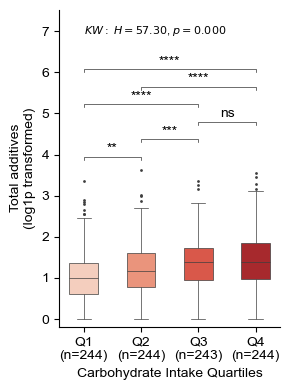

In [6]:
fig, ax = plt.subplots(figsize=(3, 4))
test_quartile_differences(
    meta,
    "carb_eaten",
    "total_additive_intake",
    extremes=False,
    palette="Reds",
    ax=ax,
    # xlabel=process_string("total_additive_intake", newLineSep=3),
    xlabel="Carbohydrate Intake Quartiles",
    log_transform=True,
)
sns.despine()
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/group_comparison_total_additives_vs_carb_eaten.png",
    dpi=300,
    bbox_inches="tight",
)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:8.837e-08 U_stat=2.144e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:4.500e-01 U_stat=2.847e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:8.380e-04 U_stat=2.446e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:9.976e-10 U_stat=2.016e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:5.461e-05 U_stat=2.348e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.117e-17 U_stat=1.643e+04
sugar_eaten_quartile -> total_additive_intake_log	Significant differences exist. Kruskal-Wallis statistic: 83.560 p-value: 0.000


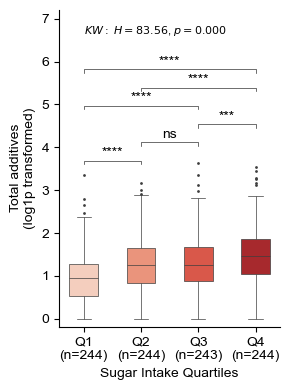

In [7]:
fig, ax = plt.subplots(figsize=(3, 4))
test_quartile_differences(
    meta,
    "sugar_eaten",
    "total_additive_intake",
    extremes=False,
    palette="Reds",
    ax=ax,
    xlabel="Sugar Intake Quartiles",
    log_transform=True,
)
sns.despine()
plt.tight_layout()

plt.savefig(
    "../figures/additive_descriptive/group_comparison_total_additives_vs_sugar_eaten.png",
    dpi=300,
    bbox_inches="tight",
)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:4.842e-04 U_stat=2.433e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:5.256e-01 U_stat=2.866e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:8.607e-04 U_stat=2.447e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:8.227e-05 U_stat=2.353e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:5.401e-05 U_stat=2.348e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.315e-12 U_stat=1.884e+04
sugar_per_1000kcal_quartile -> total_additive_intake_log	Significant differences exist. Kruskal-Wallis statistic: 52.382 p-value: 0.000


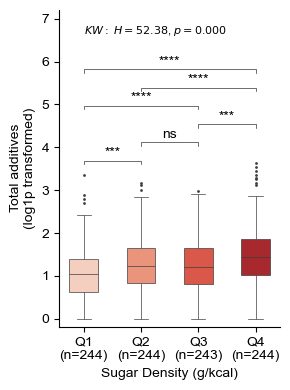

In [6]:
meta_density = meta.copy()
meta_density["sugar_per_1000kcal"] = (
    meta_density["sugar_eaten"] / meta_density["energy_kcal_eaten"]
)

fig, ax = plt.subplots(figsize=(3, 4))

test_quartile_differences(
    meta_density,
    "sugar_per_1000kcal",
    "total_additive_intake",
    extremes=False,
    palette="Reds",
    ax=ax,
    xlabel="Sugar Density (g/kcal)",
    log_transform=True,
)
sns.despine()
plt.tight_layout()

## Merged Plots (previous version)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:1.268e-04 U_stat=3.560e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:8.779e-01 U_stat=3.013e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:7.099e-03 U_stat=3.395e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:2.384e-04 U_stat=3.605e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:8.840e-03 U_stat=3.317e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.675e-09 U_stat=3.814e+04
HEI_Quartile -> total_additive_intake_log	Significant differences exist. Kruskal-Wallis statistic: 38.688 p-value: 0.000
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

<35

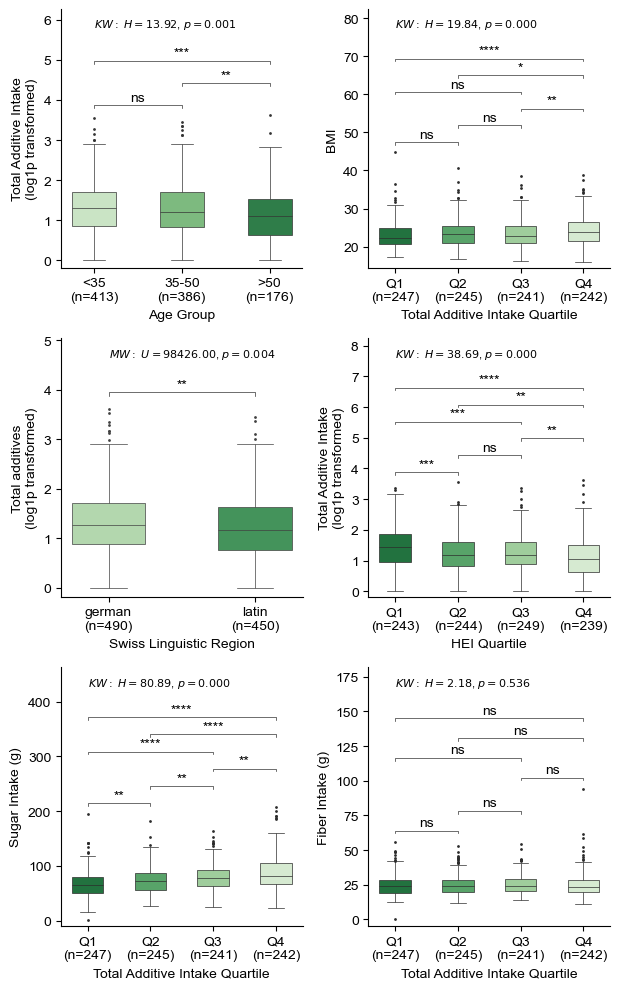

In [8]:
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(6.3, 10))

test_group_differences(
    meta,
    "HEI_Quartile",
    "total_additive_intake",
    palette="Greens_r",
    showfliers=True,
    ax=ax[1, 1],
    xlabel="HEI Quartile",
    ylabel=process_string("total_additive_intake", newLineSep=3),
    log_transform=True,
)

test_group_differences(
    meta,
    "age_group_2",
    "total_additive_intake",
    showfliers=True,
    palette="Greens",
    ax=ax[0, 0],
    xlabel="Age Group",
    ylabel=process_string("total_additive_intake", newLineSep=5),
    log_transform=True,
)

test_group_differences(
    meta[meta["language"].notna()],
    "language",
    "total_additive_intake",
    showfliers=True,
    palette="Greens",
    ax=ax[1, 0],
    xlabel="Swiss Linguistic Region",
    log_transform=True,
)


test_quartile_differences(
    meta,
    "total_additive_intake",
    "bmi",
    extremes=False,
    palette="Greens_r",
    ax=ax[0, 1],
    ylabel="BMI",
)

test_quartile_differences(
    meta,
    "total_additive_intake",
    "sugar_eaten",
    extremes=False,
    palette="Greens_r",
    ax=ax[2, 0],
    ylabel="Sugar Intake (g)",
)

test_quartile_differences(
    meta,
    "total_additive_intake",
    "fiber_eaten",
    extremes=False,
    palette="Greens_r",
    ax=ax[2, 1],
    ylabel="Fiber Intake (g)",
)

sns.despine()
plt.tight_layout()

# plt.savefig(
#     "../figures/additive_descriptive/group_comparison_total_additives_by_demographics.png",
#     dpi=300,
#     bbox_inches="tight",
# )

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

binational vs. foreign: Mann-Whitney-Wilcoxon test two-sided, P_val:3.672e-01 U_stat=2.299e+04
foreign vs. swiss: Mann-Whitney-Wilcoxon test two-sided, P_val:1.975e-02 U_stat=5.364e+04
binational vs. swiss: Mann-Whitney-Wilcoxon test two-sided, P_val:2.556e-01 U_stat=4.333e+04
swiss_citizen -> total_additive_intake	No significant differences.
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

rural vs. semi_urban: Mann-Whitney-Wilcoxon test two-sided, P_val:2.260e-01 U_stat=5.517e+03
semi_urban vs. urban: Mann-Whitney-Wilcoxon test two-sided, P_val:2.336e-01 U_stat=4.871e+04
rural vs. urban: Mann-Whitney-Wilcoxon test two-sided, P_val:4.833e-01 U_stat=2.674e+

<Axes: xlabel='Urbanity', ylabel='Total additives'>

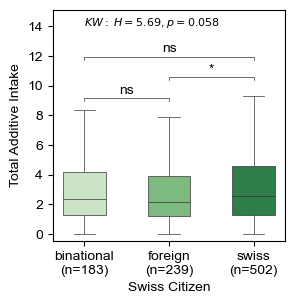

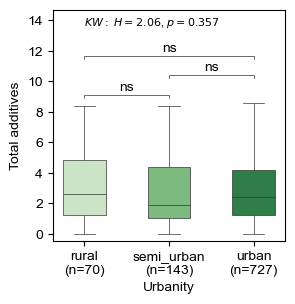

In [9]:
test_group_differences(
    meta[meta["swiss_citizen"].notna()],
    "swiss_citizen",
    "total_additive_intake",
    showfliers=False,
    palette="Greens",
    xlabel="Swiss Citizen",
    ylabel=process_string("total_additive_intake", newLineSep=5),
)

test_group_differences(
    meta[meta["urbanity"].notna()],
    "urbanity",
    "total_additive_intake",
    showfliers=False,
    palette="Greens",
    xlabel="Urbanity",
)

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

<35 vs. 35-50: Mann-Whitney-Wilcoxon test two-sided, P_val:5.894e-02 U_stat=8.586e+04
35-50 vs. >50: Mann-Whitney-Wilcoxon test two-sided, P_val:3.988e-03 U_stat=3.910e+04
<35 vs. >50: Mann-Whitney-Wilcoxon test two-sided, P_val:5.131e-05 U_stat=4.400e+04
age_group_2 -> ph_regulators_anti_caking_leavening_agents	Significant differences exist. Kruskal-Wallis statistic: 17.589 p-value: 0.000
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:5.601e-03 U_stat=3.395e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:8.238e-01 U_stat=3.003e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:8.03

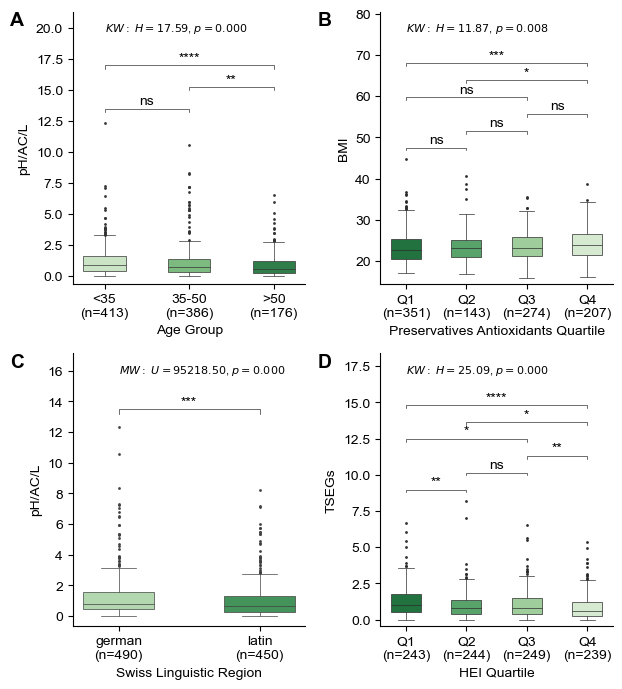

In [10]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(6.3, 7))

test_group_differences(
    meta,
    "age_group_2",
    "ph_regulators_anti_caking_leavening_agents",
    showfliers=True,
    palette="Greens",
    ax=ax[0, 0],
    xlabel="Age Group",
    ylabel=process_string_pretty_vars(
        "ph_regulators_anti_caking_leavening_agents", newLineSep=5
    ),
)


test_group_differences(
    meta,
    "HEI_Quartile",
    "thickeners_stabilizers_emulsifiers_gelling_agents",
    palette="Greens_r",
    showfliers=True,
    ax=ax[1, 1],
    xlabel="HEI Quartile",
    ylabel=process_string_pretty_vars(
        "thickeners_stabilizers_emulsifiers_gelling_agents", newLineSep=3
    ),
)

test_group_differences(
    meta[meta["language"].notna()],
    "language",
    "ph_regulators_anti_caking_leavening_agents",
    showfliers=True,
    palette="Greens",
    ax=ax[1, 0],
    xlabel="Swiss Linguistic Region",
)

test_quartile_differences(
    meta,
    "preservatives_antioxidants",
    "bmi",
    extremes=False,
    palette="Greens_r",
    ax=ax[0, 1],
    ylabel="BMI",
)

# Add text labels A, B, C, D at top left of each subplot
ax[0, 0].text(
    -0.27, 0.95, "A", transform=ax[0, 0].transAxes, fontsize=14, fontweight="bold"
)
ax[0, 1].text(
    -0.27, 0.95, "B", transform=ax[0, 1].transAxes, fontsize=14, fontweight="bold"
)
ax[1, 0].text(
    -0.27, 0.95, "C", transform=ax[1, 0].transAxes, fontsize=14, fontweight="bold"
)
ax[1, 1].text(
    -0.27, 0.95, "D", transform=ax[1, 1].transAxes, fontsize=14, fontweight="bold"
)

sns.despine()
plt.tight_layout()


# plt.savefig(
#     "../figures/additive_descriptive/group_comparison_additive_types_by_demographics.png",
#     dpi=300,
#     bbox_inches="tight",
# )

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:5.623e-03 U_stat=3.394e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:8.236e-01 U_stat=3.002e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:8.060e-03 U_stat=3.388e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:1.484e-02 U_stat=3.409e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.239e-02 U_stat=3.299e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.254e-06 U_stat=3.645e+04
HEI_Quartile -> thickeners_stabilizers_emulsifiers_gelling_agents_log	Significant differences exist. Kruskal-Wallis statistic: 25.074 p-value: 0.000
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03


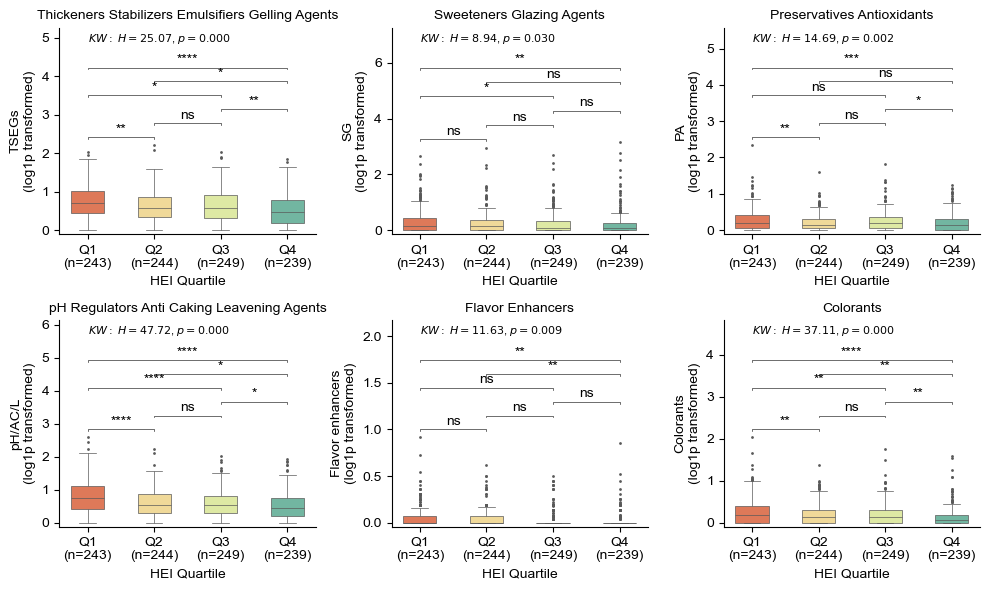

In [16]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(10, 6))
axes = axes.flatten()

for i, additive in enumerate([i for i in ADDITIVE_VARS if i != "other_additives"]):
    test_group_differences(
        meta,
        "HEI_Quartile",
        additive,
        showfliers=True,
        ax=axes[i],
        log_transform=True,
    )
    axes[i].set_title(process_string(additive), fontsize=10)

# Hide the unused subplot (if any)
if len(ADDITIVE_VARS) < len(axes):
    for j in range(len(ADDITIVE_VARS), len(axes)):
        axes[j].set_visible(False)

plt.tight_layout()
sns.despine()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

False vs. True: Mann-Whitney-Wilcoxon test two-sided, P_val:4.887e-01 U_stat=2.670e+04
has_eating_disorder -> thickeners_stabilizers_emulsifiers_gelling_agents_log	No significant differences.
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

False vs. True: Mann-Whitney-Wilcoxon test two-sided, P_val:6.649e-02 U_stat=2.168e+04
has_eating_disorder -> sweeteners_glazing_agents_log	No significant differences.
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

False vs. True: Mann-Whitney-Wilcoxon test two-sided, P_val:6.64

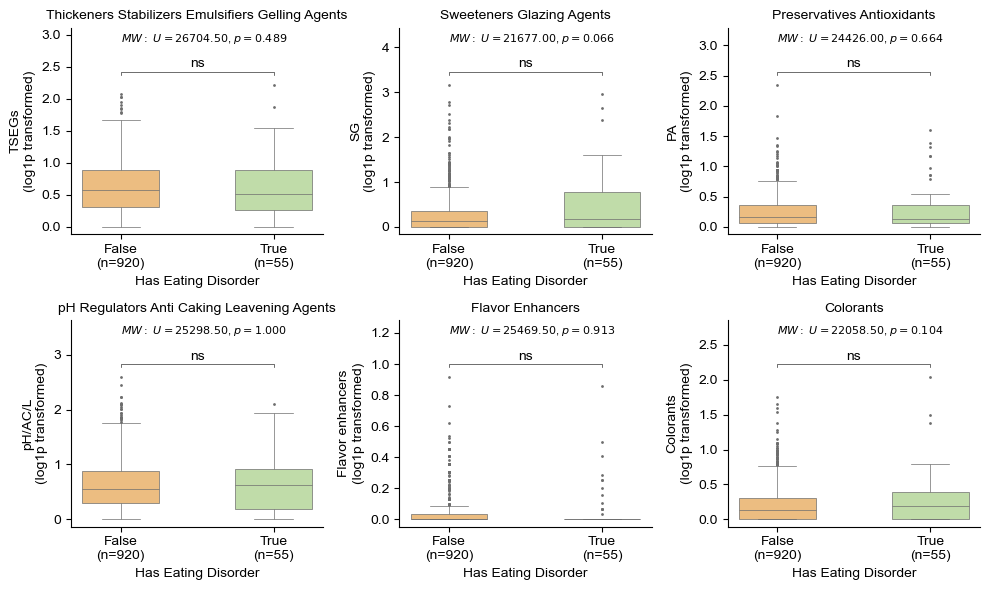

In [12]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(10, 6))
axes = axes.flatten()

for i, additive in enumerate([i for i in ADDITIVE_VARS if i != "other_additives"]):
    test_group_differences(
        meta[meta["has_eating_disorder"].notna()],
        "has_eating_disorder",
        additive,
        showfliers=True,
        ax=axes[i],
        log_transform=True,
    )
    axes[i].set_title(process_string(additive), fontsize=10)

# Hide the unused subplot (if any)
if len(ADDITIVE_VARS) < len(axes):
    for j in range(len(ADDITIVE_VARS), len(axes)):
        axes[j].set_visible(False)

plt.tight_layout()
sns.despine()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:7.443e-07 U_stat=2.206e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:5.253e-01 U_stat=2.866e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.123e-03 U_stat=2.459e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:9.830e-09 U_stat=2.075e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.274e-04 U_stat=2.403e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.190e-15 U_stat=1.731e+04
sugar_eaten_quartile -> thickeners_stabilizers_emulsifiers_gelling_agents_log	Significant differences exist. Kruskal-Wallis statistic: 72.935 p-value: 0.000
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1

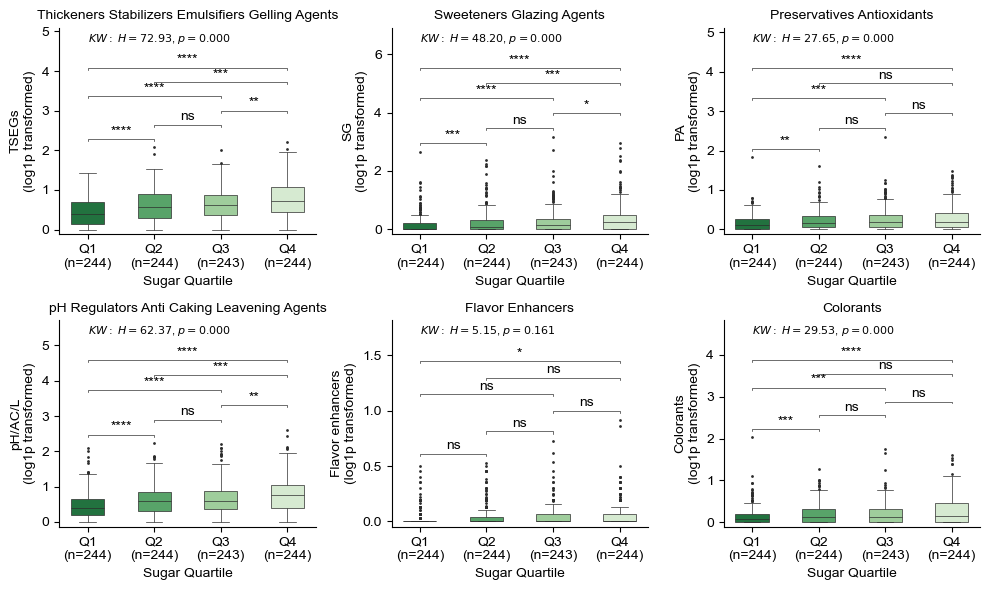

In [13]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(10, 6))
axes = axes.flatten()

var_boxplot = "sugar_eaten"

for i, additive in enumerate([i for i in ADDITIVE_VARS if i != "other_additives"]):
    test_quartile_differences(
        meta,
        var_boxplot,
        additive,
        extremes=False,
        palette="Greens_r",
        ax=axes[i],
        log_transform=True,
    )
    axes[i].set_title(process_string(additive), fontsize=10)

# Hide the unused subplot
if len(ADDITIVE_VARS) < len(axes):
    for j in range(len(ADDITIVE_VARS), len(axes)):
        axes[j].set_visible(False)

plt.tight_layout()
sns.despine()
plt.savefig(
    f"../figures/additive_descriptive/group_comparison_additive_types_by_{var_boxplot}.png",
    dpi=300,
    bbox_inches="tight",
)

## Nutrient Quartile Significant associations:

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Q1 vs. Q2: Mann-Whitney-Wilcoxon test two-sided, P_val:2.351e-03 U_stat=2.503e+04
Q2 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:1.263e-01 U_stat=3.202e+04
Q3 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:2.433e-03 U_stat=2.494e+04
Q1 vs. Q3: Mann-Whitney-Wilcoxon test two-sided, P_val:1.123e-01 U_stat=2.718e+04
Q2 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.134e-01 U_stat=2.730e+04
Q1 vs. Q4: Mann-Whitney-Wilcoxon test two-sided, P_val:1.390e-05 U_stat=2.300e+04
fat_eaten_quartile -> thickeners_stabilizers_emulsifiers_gelling_agents_log	Significant differences exist. Kruskal-Wallis statistic: 22.357 p-value: 0.000
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.0

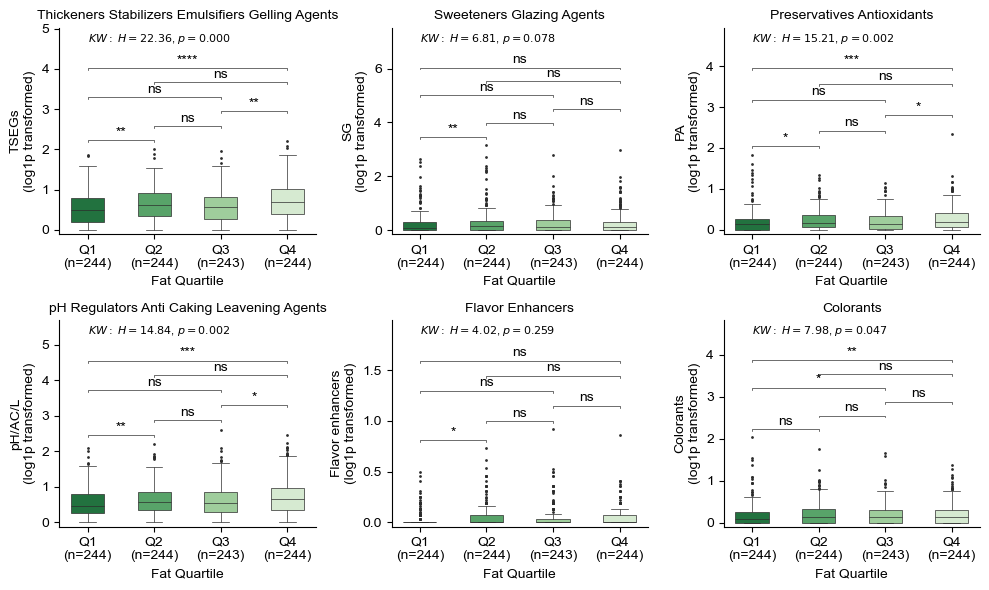

In [14]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(10, 6))
axes = axes.flatten()

var_boxplot = "fat_eaten"

for i, additive in enumerate([i for i in ADDITIVE_VARS if i != "other_additives"]):
    test_quartile_differences(
        meta,
        var_boxplot,
        additive,
        extremes=False,
        palette="Greens_r",
        ax=axes[i],
        log_transform=True,
    )
    axes[i].set_title(process_string(additive), fontsize=10)

# Hide the unused subplot (if any)
if len(ADDITIVE_VARS) < len(axes):
    for j in range(len(ADDITIVE_VARS), len(axes)):
        axes[j].set_visible(False)

plt.tight_layout()
sns.despine()